In [3]:
import hashlib
import os
import platform
import uuid
# 修改为自己的学号
STUDENT_ID = 20244080101
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
 f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] ML
[学号] 20244080101
[机器指纹] c8c5ea6ebc227d20
[RUN_ID] 20244080101-c8c5ea6ebc227d20


围绕半圆定律


第一部分
x = [-3 -2 -1  0  1  2  3]
密度 = [0.         0.         0.27566445 0.31830989 0.27566445 0.
 0.        ]

第二部分
生成的 Wigner 矩阵：
[[ 0.78960641  0.17561497 -0.04888381  0.22899248]
 [ 0.17561497  0.38371736  0.53847237 -0.08278572]
 [-0.04888381  0.53847237 -0.23473719 -0.08277991]
 [ 0.22899248 -0.08278572 -0.08277991  0.27128002]]
矩阵形状： (4, 4)
是否对称： True

第三部分
特征值（升序）：
[-0.5592213   0.14336652  0.70493285  0.92078853]

第四部分


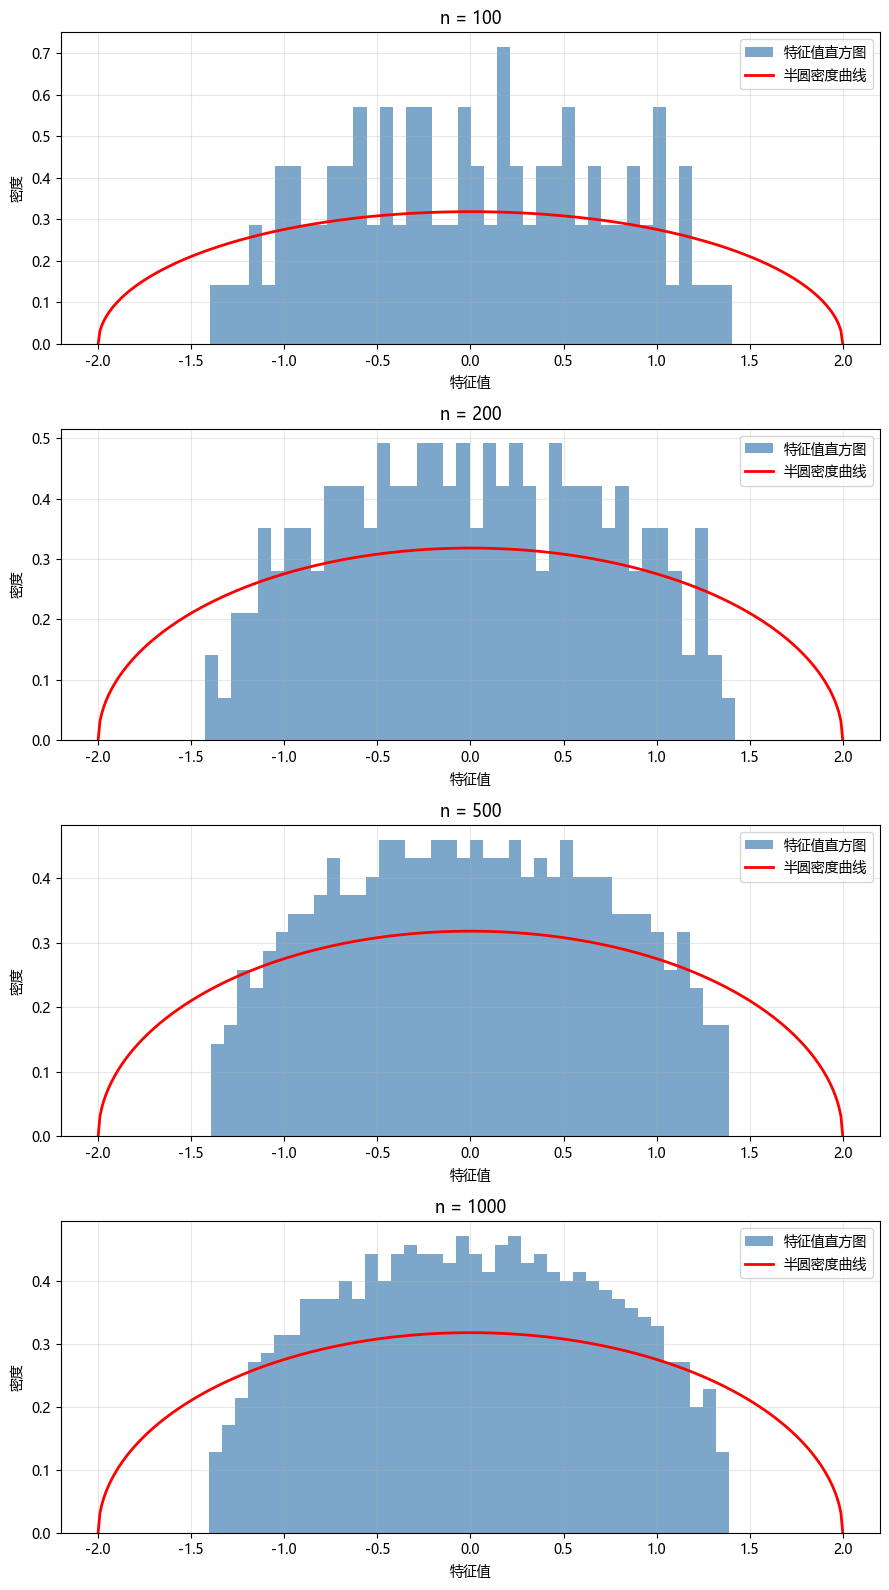

In [4]:
print("\n第一部分")
import numpy as np
import matplotlib.pyplot as plt

def wigner_density(x):
    x = np.asarray(x)
    return np.where(
        np.abs(x) <= 2,
        np.sqrt(np.maximum(0, 4 - x**2)) / (2 * np.pi),
        0.0
    )

x_test = np.array([-3, -2, -1, 0, 1, 2, 3])
print("x =", x_test)
print("密度 =", wigner_density(x_test))

print("\n第二部分")
def generate_wigner(n):
    if isinstance(n, bool) or not isinstance(n, (int, np.integer)):
        raise TypeError("n 必须是正整数")
    if n <= 0:
        raise ValueError("n 必须是正整数")

    upper = np.zeros((n, n))
    upper_indices = np.triu_indices(n, k=1)
    upper[upper_indices] = np.random.normal(
        loc=0,
        scale=1 / np.sqrt(2 * n),
        size=len(upper_indices[0])
    )
    diagonal_indices = np.diag_indices(n)
    upper[diagonal_indices] = np.random.normal(
        loc=0,
        scale=1 / np.sqrt(n),
        size=n
    )

    return upper + np.triu(upper, k=1).T

np.random.seed(42)
n = 4
z = generate_wigner(n)
print("生成的 Wigner 矩阵：")
print(z)
print("矩阵形状：", z.shape)
print("是否对称：", np.allclose(z, z.T))

print("\n第三部分")
def get_spectrum(matrix):
    return np.sort(np.linalg.eigvalsh(matrix))

eigenvalues = get_spectrum(z)
print("特征值（升序）：")
print(eigenvalues)

print("\n第四部分")
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False

np.random.seed(42)
matrix_sizes = [100, 200, 500, 1000]

fig, axes = plt.subplots(4, 1, figsize=(9, 16))

for ax, n in zip(axes, matrix_sizes):
    matrix = generate_wigner(n)
    eigenvalues = get_spectrum(matrix)

    ax.hist(
        eigenvalues,
        bins=40,
        density=True,
        color="steelblue",
        alpha=0.7,
        label="特征值直方图"
    )

    x = np.linspace(-2, 2, 400)
    ax.plot(
        x,
        wigner_density(x),
        color="red",
        linewidth=2,
        label="半圆密度曲线"
    )

    ax.set_title(f"n = {n}")
    ax.set_xlabel("特征值")
    ax.set_ylabel("密度")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

从图形上看，(n=100) 和 (n=200) 时直方图与半圆曲线仍有明显差异；到 (n\approx500) 时，整体形状已较接近半圆曲线；当 (n=1000) 时拟合通常更好。因此可以说，半圆密度大约在 (n=500) 时已能较好地拟合特征值分布。

Conway 的⽣命游戏


第一部分
棋盘：
[[0 1 0]
 [1 1 0]
 [0 0 1]]
是否有效： True

第二部分
当前棋盘：
[[0 1 0]
 [1 1 0]
 [0 0 1]]
下一步棋盘：
[[0 1 0]
 [1 1 0]
 [0 0 1]]

第三部分


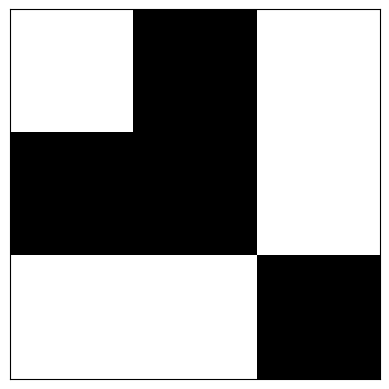

In [5]:
print("\n第一部分")
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

def is_valid_board(board):
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2 or board.size == 0:
        return False
    return np.all((board == 0) | (board == 1))

board = np.array([
    [0, 1, 0],
    [1, 1, 0],
    [0, 0, 1]
])

print("棋盘：")
print(board)
print("是否有效：", is_valid_board(board))

print("\n第二部分")
def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("board 必须是只包含 0 和 1 的非空二维 NumPy 数组")

    rows, cols = board.shape
    neighbors = np.zeros((rows, cols), dtype=int)

    for row_shift in (-1, 0, 1):
        for col_shift in (-1, 0, 1):
            if row_shift == 0 and col_shift == 0:
                continue
            neighbors += np.roll(
                np.roll(board, row_shift, axis=0),
                col_shift,
                axis=1
            )

    next_board = np.zeros_like(board)
    alive = board == 1
    dead = board == 0

    next_board[alive & ((neighbors == 2) | (neighbors == 3))] = 1
    next_board[dead & (neighbors == 3)] = 1

    return next_board

board = np.array([
    [0, 1, 0],
    [1, 1, 0],
    [0, 0, 1]
])

print("当前棋盘：")
print(board)
print("下一步棋盘：")
print(gol_step(board))

print("\n第三部分")
def draw_gol_board(board):
    if not is_valid_board(board):
        raise ValueError("board 必须是只包含 0 和 1 的非空二维 NumPy 数组")

    cmap = ListedColormap(["white", "black"])
    plt.figure()
    plt.imshow(board, cmap=cmap, vmin=0, vmax=1, interpolation="none")
    plt.xticks([])
    plt.yticks([])
    plt.show()

draw_gol_board(board)


使⽤ pandas DataFrame

In [6]:
print("\n第一部分")
import pandas as pd

df = pd.read_csv("Iris.csv")

print("数据点数量：", len(df))
print("\n每列的数据类型：")
print(df.dtypes)
print("\n列名：")
print(df.columns.tolist())
print("\n花种数量：", df["Species"].nunique())
print("\n花种名称：")
print(df["Species"].unique())
print("\n各花种数量：")
print(df["Species"].value_counts())


print("\n第二部分")
print("修改前：")
print(df.loc[[34, 37]])

df.loc[34] = [35, 4.9, 3.1, 1.5, 0.2, "Iris-setosa"]
df.loc[37] = [38, 4.9, 3.6, 1.4, 0.1, "Iris-setosa"]

print("\n修正后的第35行：")
print(df.loc[34])
print("\n修正后的第38行：")
print(df.loc[37])


print("\n第三部分")
df["Petal.Ratio"] = df["PetalLengthCm"] / df["PetalWidthCm"]
df["Sepal.Ratio"] = df["SepalLengthCm"] / df["SepalWidthCm"]

print("新增比例列后的前5行：")
print(df[["PetalLengthCm", "PetalWidthCm", "Petal.Ratio",
          "SepalLengthCm", "SepalWidthCm", "Sepal.Ratio"]].head())


print("\n第四部分")
df.to_csv("iris_corrected.csv", index=False)
print("已保存为 iris_corrected.csv")


print("\n第五部分")
summary = df.groupby("Species")[["Petal.Ratio", "Sepal.Ratio"]].agg(
    ["mean", "median", "min", "max", "std"]
)

print("按花种分组的统计结果：")
print(summary)


第一部分
数据点数量： 150

每列的数据类型：
Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species           object
dtype: object

列名：
['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']

花种数量： 3

花种名称：
['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']

各花种数量：
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

第二部分
修改前：
    Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
34  35            4.9           3.1            1.5           0.1  Iris-setosa
37  38            4.9           3.1            1.5           0.1  Iris-setosa

修正后的第35行：
Id                        35
SepalLengthCm            4.9
SepalWidthCm             3.1
PetalLengthCm            1.5
PetalWidthCm             0.2
Species          Iris-setosa
Name: 34, dtype: object

修正后的第38行：
Id                        38
SepalLengthCm            4.9
SepalWidthCm          